# 11. Meta-articles (added 8/11)

**Question.** If every training example is a *meta-article* (the leads of many articles of ONE outlet in one text) and
every outlet has the same number of them, do the main models (TF-IDF, Qwen3-8B, Mistral-24B, ModernBERT) predict the
NewsGuard score better than when they read single articles?

**Fixed before the results** (details in `meta.py`): a meta-article = leads (first 120 words) of articles of the outlet in
random order up to 2,400 words; 10 per outlet, built from the outlet's own articles only, the same way for training and
test outlets. Same outer folds, inner folds and inner criterion as before. Frozen models: ridge and the small neural
network of step 10. ModernBERT: fresh meta-articles every epoch (6 per outlet), mean pooling, Huber loss, lr 3e-5,
at most 10 epochs, epoch chosen on 20% of the training outlets kept apart. Outlet score = mean over its 10 meta-articles.

**Compared with** the same model on whole articles (steps 7 and 10), all articles, on the same 226 outlets; paired
bootstrap over outlets (1,000, seed 7). Note: meta-articles read only the leads (about 2,400 words per meta-article,
24,000 per outlet), single articles are read in full.

In [1]:
import warnings

import numpy as np
import pandas as pd

import common as C

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
C.OUT.mkdir(parents=True, exist_ok=True)
LOG = C.OUT / "log.txt"
print(C.environment())
import matplotlib.pyplot as plt

import boost as BO
import boost_eval as BE
import meta as ME

art, outlets, rows = BO.load()
M, mrows = ME.load_meta()
print(f"{len(M):,} meta-articles; articles per meta-article: median {M.articles.median():.0f}; words: median {M.words.median():.0f}")
done = {m: len(list((ME.PRED / m).glob("fold*.csv.gz"))) for m in ME.MODELS}
print("folds saved:", done)
err = ME.OUT / "errors.txt"
print(open(err).read()[-3000:] if err.exists() else "no errors")

{'python': '3.12.3', 'seed': 42, 'split seed': 1, 'numpy': '2.5.4', 'pandas': '3.0.6', 'sklearn': '1.9.1', 'scipy': '1.18.1', 'torch': '2.5.1+cu121', 'transformers': '4.51.3', 'bitsandbytes': '0.50.2', 'trafilatura': '2.3.1'}


/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


2,260 meta-articles; articles per meta-article: median 20; words: median 2400
folds saved: {'TF-IDF': 5, 'Qwen3-8B · ridge': 5, 'Qwen3-8B · mlp': 5, 'Mistral-24B · ridge': 5, 'Mistral-24B · mlp': 5, 'ModernBERT': 5}
==== embed Qwen3-8B
Traceback (most recent call last):
  File "/home/fabio.pinelli/John/Tentativo20/meta_run.py", line 21, in guarded
    f(*a); return 0
    ^^^^^
  File "/home/fabio.pinelli/John/Tentativo20/meta.py", line 103, in embed
    np.save(f, MO20.qwen_embeddings(texts, QWEN, 32768, LOG))
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/fabio.pinelli/John/Tentativo20/models.py", line 114, in qwen_embeddings
    h = F.normalize(m(**enc).last_hidden_state[:, -1].float(), p=2, dim=1).cpu().numpy()
                    ^^^^^^^^
  File "/home/fabio.pinelli/John/johnVenv/lib/python3.12/site-packages/torch/nn/modules/module.py", line 1736, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

## Meta-articles against single articles (all articles / all 10 meta-articles)

In [2]:
idx = np.vstack([np.arange(len(outlets))[None, :], np.random.default_rng(7).integers(0, len(outlets), (BE.B, len(outlets)))])
V = {}
for name in [m for m in ME.MODELS if done[m] == 5]:
    V[(name, "meta")] = BE._one(ME.meta_matrix(name, outlets, "all"), name, "all", outlets, idx)[2]
    V[(name, "articles")] = BE._one(ME.article_matrix(name, outlets, art, rows), name, "all", outlets, idx)[2]
rows_out = []
for (name, how), res in V.items():
    for (score, mes), v in res.items():
        r = {"model": name, "input": how, "score": score, "measure": mes, "value": v[0]}
        other = V.get((name, "articles"))
        if how == "meta" and other is not None:
            d = v - other[(score, mes)]; lo, hi = np.percentile(d[1:], [2.5, 97.5])
            r.update({"meta − articles": d[0], "low": lo, "high": hi,
                      "better": bool(hi < 0) if mes in BE.LOWER else bool(lo > 0), "worse": bool(lo > 0) if mes in BE.LOWER else bool(hi < 0)})
        tf = V.get(("TF-IDF", "articles"))
        if tf is not None and (name, how) != ("TF-IDF", "articles"):
            d = v - tf[(score, mes)]; lo, hi = np.percentile(d[1:], [2.5, 97.5])
            r["beats TF-IDF (articles)"] = bool(hi < 0) if mes in BE.LOWER else bool(lo > 0)
        rows_out.append(r)
T = pd.DataFrame(rows_out); T.to_csv(ME.OUT / "results.csv", index=False)

In [3]:
def table(score):
    """✓ = meta-articles significantly better than the same model on articles, ✗ = significantly worse."""
    d = T[T.score == score].copy()
    d["text"] = [f"{v:.3f}" if m in ("Spearman", "Kendall") else f"{v:.1f}" for v, m in zip(d.value, d.measure)]
    d["text"] += np.where(d.get("better", False) == True, " ✓", "") + np.where(d.get("worse", False) == True, " ✗", "")
    return d.pivot_table(index=["model", "input"], columns="measure", values="text", aggfunc="first")[BE.MEASURES]


table("stretched")

measure                      Spearman  Kendall     MAE within 20
model               input                                       
Mistral-24B · mlp   articles    0.749    0.575    14.2      74.8
                    meta      0.669 ✗  0.495 ✗  16.4 ✗      71.2
Mistral-24B · ridge articles    0.735    0.554    15.2      75.2
                    meta        0.712    0.530    15.9      70.8
ModernBERT          articles    0.602    0.444    18.1      66.4
                    meta        0.570    0.416    18.6      68.1
Qwen3-8B · mlp      articles    0.718    0.539    15.7      76.1
                    meta      0.620 ✗  0.453 ✗  18.1 ✗    67.3 ✗
Qwen3-8B · ridge    articles    0.726    0.544    15.3      75.7
                    meta      0.596 ✗  0.436 ✗  18.6 ✗    69.5 ✗
TF-IDF              articles    0.696    0.518    16.3      70.8
                    meta        0.644    0.474    17.3      67.3

In [4]:
table("normal")

measure                      Spearman  Kendall     MAE within 20
model               input                                       
Mistral-24B · mlp   articles    0.751    0.563    14.8      73.9
                    meta      0.676 ✗  0.492 ✗    15.6    67.7 ✗
Mistral-24B · ridge articles    0.735    0.538    15.7      68.6
                    meta        0.713    0.520    15.7      70.8
ModernBERT          articles    0.605    0.430    17.7      61.9
                    meta        0.534    0.370    18.3      63.3
Qwen3-8B · mlp      articles    0.717    0.521    16.4      67.7
                    meta      0.621 ✗  0.444 ✗  17.7 ✗    60.6 ✗
Qwen3-8B · ridge    articles    0.721    0.525    16.1      69.0
                    meta      0.587 ✗  0.419 ✗  17.6 ✗      64.6
TF-IDF              articles    0.691    0.496    17.7      61.1
                    meta      0.631 ✗  0.448 ✗  18.5 ✗      59.3

In [5]:
T[(T.input == "meta") & T["meta − articles"].notna()].round(3)[["model", "score", "measure", "meta − articles", "low", "high", "better", "worse"]]

,model,score,measure,meta − articles,low,high,better,worse
0,TF-IDF,normal,Spearman,-0.060,-0.118,-0.011,False,True
1,TF-IDF,normal,Kendall,-0.048,-0.096,-0.003,False,True
2,TF-IDF,normal,MAE,0.843,0.247,1.452,False,True
3,TF-IDF,normal,within 20,-1.770,-5.752,2.212,False,False
4,TF-IDF,stretched,Spearman,-0.053,-0.111,0.001,False,False
5,TF-IDF,stretched,Kendall,-0.044,-0.094,0.004,False,False
6,TF-IDF,stretched,MAE,1.034,-0.482,2.603,False,False
7,TF-IDF,stretched,within 20,-3.540,-9.303,2.655,False,False
16,Qwen3-8B · ridge,normal,Spearman,-0.134,-0.209,-0.065,False,True
17,Qwen3-8B · ridge,normal,Kendall,-0.106,-0.167,-0.051,False,True


## How many meta-articles are needed (stretched score; 1 meta-article ≈ 20 leads)

In [6]:
rows_k = []
for name in [m for m in ME.MODELS if done[m] == 5]:
    for k in ME.K_META:
        res = BE._one(ME.meta_matrix(name, outlets, k), name, str(k), outlets, idx[:1])[2]
        rows_k.append({"model": name, "meta-articles": str(k), **{m: res[("stretched", m)][0] for m in BE.MEASURES}})
pd.DataFrame(rows_k).pivot_table(index="model", columns="meta-articles", values="Spearman")[[str(k) for k in ME.K_META]].round(3)

meta-articles,1,2,3,5,all
model,,,,,
Mistral-24B · mlp,0.665,0.668,0.670,0.672,0.669
Mistral-24B · ridge,0.703,0.708,0.709,0.712,0.712
ModernBERT,0.546,0.559,0.567,0.572,0.570
Qwen3-8B · mlp,0.551,0.597,0.599,0.617,0.620
Qwen3-8B · ridge,0.478,0.534,0.558,0.581,0.596
TF-IDF,0.599,0.625,0.627,0.636,0.644


## ModernBERT: Spearman on the outlets kept apart, epoch by epoch

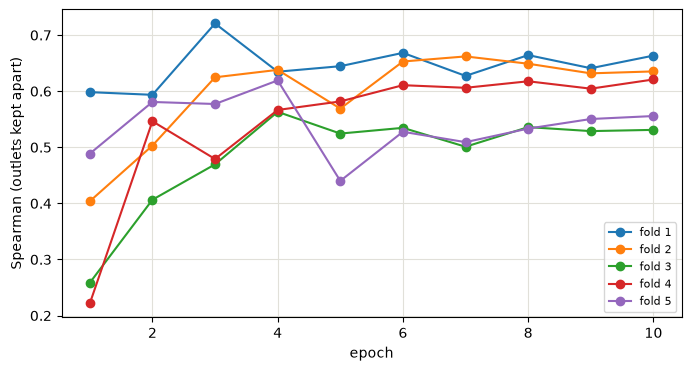

fold,1,2,3,4,5
epoch,,,,,
1,0.598,0.404,0.258,0.222,0.489
2,0.594,0.503,0.406,0.546,0.581
3,0.721,0.625,0.470,0.479,0.577
4,0.635,0.638,0.563,0.567,0.619
5,0.645,0.569,0.524,0.582,0.440
6,0.668,0.653,0.535,0.611,0.528
7,0.627,0.662,0.501,0.606,0.509
8,0.664,0.649,0.536,0.618,0.533
9,0.641,0.632,0.529,0.604,0.550


In [7]:
curves = [pd.read_csv(f) for f in sorted((ME.PRED / "ModernBERT").glob("curve_fold*.csv"))]
if curves:
    C_ = pd.concat(curves)
    fig, ax = plt.subplots(figsize=(8, 4))
    for f, d in C_.groupby("fold"):
        ax.plot(d.epoch, d["validation Spearman"], "o-", label=f"fold {f}")
    ax.set_xlabel("epoch"); ax.set_ylabel("Spearman (outlets kept apart)"); ax.legend(fontsize=8); ax.grid(color="#e1e0d9")
    plt.show()
    display(C_.pivot_table(index="epoch", columns="fold", values="validation Spearman").round(3))

## Settings chosen on the inner folds

In [8]:
for m in ME.MODELS[:-1]:
    for f in sorted((ME.PRED / m).glob("inner_fold*.csv")):
        d = pd.read_csv(f); print(m, f.stem, d.loc[d.chosen].drop(columns=["chosen"]).to_dict("records"))

TF-IDF inner_fold1 [{'fold': 1, 'alpha': 0.0003, 'inner Spearman': 0.609102600584888}]
TF-IDF inner_fold2 [{'fold': 2, 'alpha': 0.0003, 'inner Spearman': 0.5380327350163633}]
TF-IDF inner_fold3 [{'fold': 3, 'alpha': 0.003, 'inner Spearman': 0.4822279743851545}]
TF-IDF inner_fold4 [{'fold': 4, 'alpha': 0.0001, 'inner Spearman': 0.5512684560478783}]
TF-IDF inner_fold5 [{'fold': 5, 'alpha': 0.0001, 'inner Spearman': 0.5942092721612846}]
Qwen3-8B · ridge inner_fold1 [{'weights': 'none', 'alpha': 0.01, 'inner Spearman': 0.607311848826776, 'fold': 1}]
Qwen3-8B · ridge inner_fold2 [{'weights': 'none', 'alpha': 1000.0, 'inner Spearman': 0.5536995163464495, 'fold': 2}]
Qwen3-8B · ridge inner_fold3 [{'weights': 'none', 'alpha': 0.01, 'inner Spearman': 0.5614407984416089, 'fold': 3}]
Qwen3-8B · ridge inner_fold4 [{'weights': 'none', 'alpha': 0.01, 'inner Spearman': 0.5874681032990575, 'fold': 4}]
Qwen3-8B · ridge inner_fold5 [{'weights': 'none', 'alpha': 1000.0, 'inner Spearman': 0.64923572801956

## In short

In [9]:
for score in ["stretched", "normal"]:
    d = T[(T.score == score) & (T.measure.isin(["Spearman", "MAE"]))].pivot_table(index="model", columns=["measure", "input"], values="value")
    print(score); print(d.round(3).to_string(), "\n")
s = T[(T.input == "meta") & T["meta − articles"].notna()]
print("meta better than articles (significant):", s.better.sum(), "| worse:", s.worse.sum(), "| of", len(s))

stretched
measure                  MAE         Spearman       
input               articles    meta articles   meta
model                                               
Mistral-24B · mlp     14.197  16.444    0.749  0.669
Mistral-24B · ridge   15.248  15.872    0.735  0.712
ModernBERT            18.131  18.649    0.602  0.570
Qwen3-8B · mlp        15.651  18.137    0.718  0.620
Qwen3-8B · ridge      15.293  18.612    0.726  0.596
TF-IDF                16.287  17.321    0.696  0.644 

normal
measure                  MAE         Spearman       
input               articles    meta articles   meta
model                                               
Mistral-24B · mlp     14.830  15.555    0.751  0.676
Mistral-24B · ridge   15.736  15.665    0.735  0.713
ModernBERT            17.677  18.327    0.605  0.534
Qwen3-8B · mlp        16.436  17.747    0.717  0.621
Qwen3-8B · ridge      16.074  17.555    0.721  0.587
TF-IDF                17.651  18.494    0.691  0.631 

meta better than articles